# Football Player Statistics

This mini-project explores football player and team statistics using **Pandas, NumPy, Matplotlib and Seaborn**. It also demonstrates basic web scraping with Python's built-in `urllib` and `html.parser` libraries.

**Dataset:** `players_data_light-2025_2026.csv`

Keep the CSV file in the same folder as this notebook. Run the notebook from top to bottom using **Kernel → Restart Kernel and Run All Cells**.

The dataset contains player-team records from five competitions. A player may appear in more than one row if their records are listed for different teams.

## 1. Import libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 2. Load and clean the dataset

This section checks the file shape, column names, data types, missing values and duplicate rows. It then cleans text fields, converts important columns to numbers, removes rows without a player or team, fills missing values in selected statistics, and checks for negative values.


In [7]:

file_name = "players_data_light-2025_2026.csv"

if not os.path.exists(file_name):
    raise FileNotFoundError(
        f"'{file_name}' was not found. Keep the CSV file in the same folder as this notebook."
    )

data = pd.read_csv(file_name)

print("Original dataset shape:", data.shape)
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])
print("\nColumn names:")
print(data.columns.tolist())

print("\nFirst five rows:")
display(data.head())

print("\nDataset information:")
data.info()

print("\nMissing values before cleaning:")
print(data.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", data.duplicated().sum())

required_columns = [
    "Player", "Squad", "Age", "MP", "Starts", "Min", "90s",
    "Gls", "Ast", "Sh", "SoT", "CrdY", "CrdR",
    "Nation", "Pos", "Comp"
]
missing_columns = [column for column in required_columns if column not in data.columns]

if missing_columns:
    raise ValueError(f"Required columns missing from the CSV: {missing_columns}")

original_rows = len(data)
data = data.drop_duplicates().copy()


for column in ["Player", "Squad", "Nation", "Pos", "Comp"]:
    data[column] = data[column].astype("string").str.strip()

data = data.dropna(subset=["Player", "Squad"])
data = data[(data["Player"] != "") & (data["Squad"] != "")].copy()


number_columns = [
    "Age", "MP", "Starts", "Min", "90s", "Gls", "Ast",
    "Sh", "SoT", "CrdY", "CrdR"
]
for column in number_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

print("\nMissing values in selected numeric columns before handling:")
print(data[number_columns].isnull().sum())


count_columns = ["MP", "Starts", "Min", "90s", "Gls", "Ast", "Sh", "SoT", "CrdY", "CrdR"]
data[count_columns] = data[count_columns].fillna(0)


if data["Age"].notna().any():
    data["Age"] = data["Age"].fillna(data["Age"].median())


for column in number_columns:
    data = data[data[column].isna() | (data[column] >= 0)]

invalid_shot_rows = data["SoT"] > data["Sh"]
print("\nRows where shots on target exceed total shots:", int(invalid_shot_rows.sum()))
data = data[~invalid_shot_rows].copy()

data = data.reset_index(drop=True)

if data.empty:
    raise ValueError("No valid records remain after cleaning. Check the dataset.")

print("\nRows before cleaning:", original_rows)
print("Rows after cleaning:", len(data))
print("Rows removed:", original_rows - len(data))
print("Unique player names:", data["Player"].nunique())
print("Player-team records:", len(data))
print("Teams:", data["Squad"].nunique())
print("Remaining duplicate rows:", data.duplicated().sum())

print("\nMissing values in selected numeric columns after handling:")
print(data[number_columns].isnull().sum())

print("\nCleaned data preview:")
display(data.head())

Original dataset shape: (2839, 53)
Number of rows: 2839
Number of columns: 53

Column names:
['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Crs', 'TklW', 'Int', 'Fld', 'CrdY_stats_misc', 'CrdR_stats_misc', '2CrdY', 'Fls', 'OG', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm']

First five rows:


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR,G+A-PK,Sh,SoT,SoT%,Sh/90,...,PK_stats_shooting,PKatt_stats_shooting,Crs,TklW,Int,Fld,CrdY_stats_misc,CrdR_stats_misc,2CrdY,Fls,OG,GA,GA90,SoTA,Saves,Save%,W,D,L,CS,CS%,PKatt_stats_keeper,PKA,PKsv,PKm
0,1,Brenden Aaronson,us USA,"MF,FW",Leeds United,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,9,4,0,0,3,0,0.33,47,17,36.2,1.73,...,0,0,37,27,17,51,3,0,0,20,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,0.2,0,0,0,0,0,0,0,0,0.00,0,0,NaN,0.00,...,0,0,0,0,1,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Zach Abbott,eng ENG,DF,Nottingham Forest,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,0,0,0,0,0,0,0.00,0,0,NaN,0.00,...,0,0,3,4,2,1,0,0,0,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Jones El-Abdellaoui,ma MAR,"MF,FW",Celta Vigo,es La Liga,19.0,2006.0,22,4,681,7.6,2,0,2,2,0,0,0,0,0.26,17,4,23.5,2.25,...,0,0,30,3,3,3,0,0,0,7,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,138,1.5,0,0,0,0,0,0,1,0,0.00,4,1,25.0,2.61,...,0,0,1,1,2,0,1,0,0,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2839 entries, 0 to 2838
Data columns (total 53 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Rk                    2839 non-null   int64  
 1   Player                2839 non-null   str    
 2   Nation                2836 non-null   str    
 3   Pos                   2839 non-null   str    
 4   Squad                 2839 non-null   str    
 5   Comp                  2839 non-null   str    
 6   Age                   2837 non-null   float64
 7   Born                  2837 non-null   float64
 8   MP                    2839 non-null   int64  
 9   Starts                2839 non-null   int64  
 10  Min                   2839 non-null   int64  
 11  90s                   2839 non-null   float64
 12  Gls                   2839 non-null   int64  
 13  Ast                   2839 non-null   int64  
 14  G+A                   2839 non-null   int64  
 15  G-PK      

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR,G+A-PK,Sh,SoT,SoT%,Sh/90,...,PK_stats_shooting,PKatt_stats_shooting,Crs,TklW,Int,Fld,CrdY_stats_misc,CrdR_stats_misc,2CrdY,Fls,OG,GA,GA90,SoTA,Saves,Save%,W,D,L,CS,CS%,PKatt_stats_keeper,PKA,PKsv,PKm
0,1,Brenden Aaronson,us USA,"MF,FW",Leeds United,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,9,4,0,0,3,0,0.33,47,17,36.2,1.73,...,0,0,37,27,17,51,3,0,0,20,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,0.2,0,0,0,0,0,0,0,0,0.00,0,0,NaN,0.00,...,0,0,0,0,1,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Zach Abbott,eng ENG,DF,Nottingham Forest,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,0,0,0,0,0,0,0.00,0,0,NaN,0.00,...,0,0,3,4,2,1,0,0,0,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Jones El-Abdellaoui,ma MAR,"MF,FW",Celta Vigo,es La Liga,19.0,2006.0,22,4,681,7.6,2,0,2,2,0,0,0,0,0.26,17,4,23.5,2.25,...,0,0,30,3,3,3,0,0,0,7,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,138,1.5,0,0,0,0,0,0,1,0,0.00,4,1,25.0,2.61,...,0,0,1,1,2,0,1,0,0,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. NumPy calculations and summary statistics

This section uses NumPy arrays and functions to calculate totals, averages, median, standard deviation, percentiles, shot accuracy and player rates.


In [8]:

data["Goal_Contribution"] = data["Gls"] + data["Ast"]

data["Goals_per_90"] = np.where(
    data["Min"] > 0, data["Gls"] * 90 / data["Min"], 0
)
data["Assists_per_90"] = np.where(
    data["Min"] > 0, data["Ast"] * 90 / data["Min"], 0
)
data["Shots_per_90"] = np.where(
    data["Min"] > 0, data["Sh"] * 90 / data["Min"], 0
)
data["Goal_Contribution_per_90"] = np.where(
    data["Min"] > 0, data["Goal_Contribution"] * 90 / data["Min"], 0
)
data["Shot_Accuracy"] = np.where(
    data["Sh"] > 0, data["SoT"] * 100 / data["Sh"], 0
)


goals = data["Gls"].to_numpy()
assists = data["Ast"].to_numpy()
minutes = data["Min"].to_numpy()
shots = data["Sh"].to_numpy()
shots_on_target = data["SoT"].to_numpy()
contributions = goals + assists

print("FOOTBALL PLAYER STATISTICS")
print("Player-team records:", len(data))
print("Unique player names:", data["Player"].nunique())
print("Teams:", data["Squad"].nunique())
print("Competitions:", data["Comp"].nunique())
print("Total goals:", int(np.sum(goals)))
print("Total assists:", int(np.sum(assists)))
print("Total goal contributions:", int(np.sum(contributions)))
print("Average goals per player-team record:", round(float(np.mean(goals)), 2))
print("Median goals:", round(float(np.median(goals)), 2))
print("Highest goals in a player-team record:", int(np.max(goals)))
print("Lowest goals in a player-team record:", int(np.min(goals)))
print("Standard deviation of goals:", round(float(np.std(goals)), 2))
print("Records with at least 10 goals:", int(np.sum(goals >= 10)))
print("Records with at least 5 assists:", int(np.sum(assists >= 5)))
print("Total minutes played:", int(np.sum(minutes)))
print("Total shots:", int(np.sum(shots)))
print("Total shots on target:", int(np.sum(shots_on_target)))

overall_shot_accuracy = (
    np.sum(shots_on_target) * 100 / np.sum(shots)
    if np.sum(shots) > 0 else 0
)
print("Overall shot accuracy (%):", round(float(overall_shot_accuracy), 2))
print("Goal average for top 25 player-team records:", round(float(np.mean(np.sort(goals)[-25:])), 2))

print("\nTop 10 goal scorers")
display(
    data.sort_values("Gls", ascending=False)[
        ["Player", "Squad", "Gls", "Ast", "Goal_Contribution", "Goals_per_90"]
    ].head(10)
)

print("\nTop 10 goal contributions")
display(
    data.sort_values("Goal_Contribution", ascending=False)[
        ["Player", "Squad", "Gls", "Ast", "Goal_Contribution"]
    ].head(10)
)

print("\nTop 10 players by goals per 90 minutes (minimum 450 minutes)")
regular_players = data[data["Min"] >= 450]
display(
    regular_players.sort_values("Goals_per_90", ascending=False)[
        ["Player", "Squad", "Min", "Gls", "Goals_per_90"]
    ].head(10)
)

print("\nNumPy percentile values for goals:")
print("25th percentile:", round(float(np.percentile(goals, 25)), 2))
print("50th percentile:", round(float(np.percentile(goals, 50)), 2))
print("75th percentile:", round(float(np.percentile(goals, 75)), 2))

FOOTBALL PLAYER STATISTICS
Player-team records: 2839
Unique player names: 2687
Teams: 96
Competitions: 5
Total goals: 4714
Total assists: 3291
Total goal contributions: 8005
Average goals per player-team record: 1.66
Median goals: 0.0
Highest goals in a player-team record: 36
Lowest goals in a player-team record: 0
Standard deviation of goals: 2.93
Records with at least 10 goals: 93
Records with at least 5 assists: 162
Total minutes played: 3459549
Total shots: 44038
Total shots on target: 15106
Overall shot accuracy (%): 34.3
Goal average for top 25 player-team records: 18.08

Top 10 goal scorers


,Player,Squad,Gls,Ast,Goal_Contribution,Goals_per_90
1319,Harry Kane,Bayern Munich,36,5,41,1.363063
1104,Erling Haaland,Manchester City,27,8,35,0.822892
1701,Kylian Mbappé,Real Madrid,25,5,30,0.865718
1847,Vedat Muriqi,Mallorca,23,1,24,0.661765
2580,Igor Thiago,Brentford,22,1,23,0.603291
1486,Esteban Lepaul,Rennes,20,5,25,0.716846
2656,Deniz Undav,Stuttgart,19,7,26,0.763052
1088,Serhou Guirassy,Dortmund,17,1,18,0.654685
1663,Lautaro Martínez,Inter,17,6,23,0.708661
391,Ante Budimir,Osasuna,17,0,17,0.520762



Top 10 goal contributions


,Player,Squad,Gls,Ast,Goal_Contribution
1319,Harry Kane,Bayern Munich,36,5,41
1104,Erling Haaland,Manchester City,27,8,35
1985,Michael Olise,Bayern Munich,15,19,34
872,Bruno Fernandes,Manchester Utd,9,21,30
1701,Kylian Mbappé,Real Madrid,25,5,30
708,Luis Díaz,Bayern Munich,15,14,29
2783,Lamine Yamal,Barcelona,16,11,27
2656,Deniz Undav,Stuttgart,19,7,26
1486,Esteban Lepaul,Rennes,20,5,25
1847,Vedat Muriqi,Mallorca,23,1,24



Top 10 players by goals per 90 minutes (minimum 450 minutes)


,Player,Squad,Min,Gls,Goals_per_90
1319,Harry Kane,Bayern Munich,2377,36,1.363063
2501,Orri Steinn Óskarsson,Real Sociedad,835,9,0.970060
860,Ansu Fati,Monaco,1093,11,0.905764
406,Jonathan Burkardt,Eintracht Frankfurt,1336,13,0.875749
1701,Kylian Mbappé,Real Madrid,2599,25,0.865718
1610,Donyell Malen,Roma,1467,14,0.858896
2183,Raphinha,Barcelona,1380,13,0.847826
667,Ousmane Dembélé,Paris Saint-Germain,1063,10,0.846660
1104,Erling Haaland,Manchester City,2953,27,0.822892
2016,William Osula,Newcastle United,819,7,0.769231



NumPy percentile values for goals:
25th percentile: 0.0
50th percentile: 0.0
75th percentile: 2.0


## 4. Matplotlib: top goal scorers

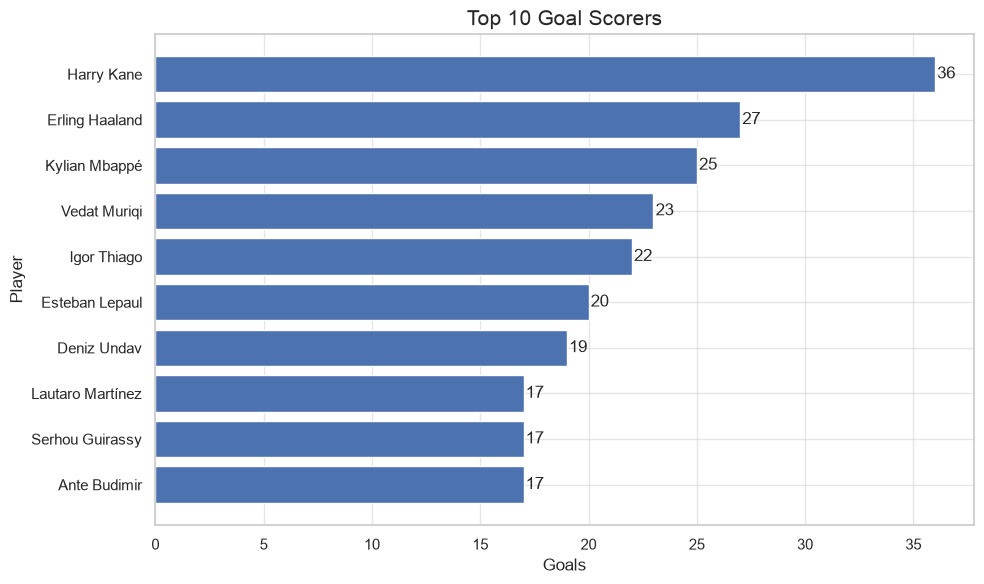

In [9]:
top = data.nlargest(10, "Gls").sort_values("Gls")

plt.figure(figsize=(10, 6))
bars = plt.barh(top["Player"], top["Gls"])
plt.title("Top 10 Goal Scorers", fontsize=15)
plt.xlabel("Goals")
plt.ylabel("Player")

for bar in bars:
    value = bar.get_width()
    plt.text(value + 0.1, bar.get_y() + bar.get_height() / 2,
             f"{value:.0f}", va="center")

plt.tight_layout()
plt.savefig("top_goal_scorers.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Matplotlib: goals by team

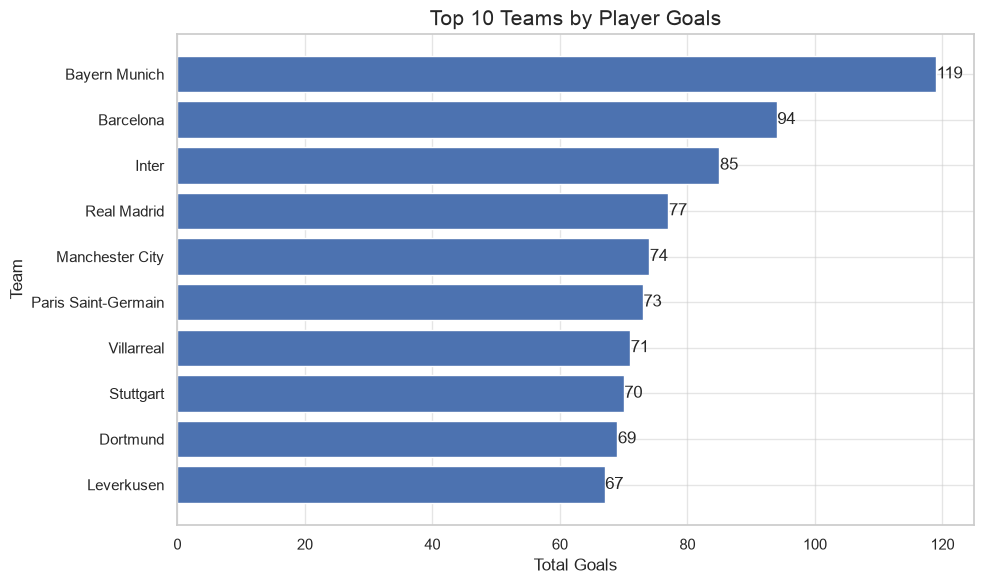

In [10]:
team_goals = (
    data.groupby("Squad")["Gls"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
bars = plt.barh(team_goals.index, team_goals.values)
plt.title("Top 10 Teams by Player Goals", fontsize=15)
plt.xlabel("Total Goals")
plt.ylabel("Team")

for bar in bars:
    value = bar.get_width()
    plt.text(value + 0.1, bar.get_y() + bar.get_height() / 2,
             f"{value:.0f}", va="center")

plt.tight_layout()
plt.savefig("team_goals.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Seaborn: shots and goals

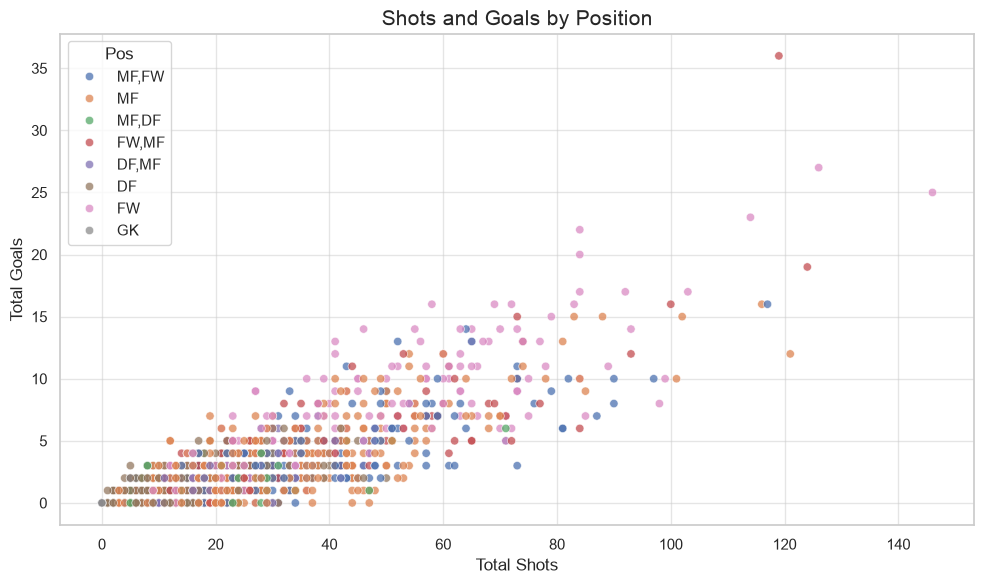

In [11]:
plot_data = data[data["Min"] >= 450].copy()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_data,
    x="Sh",
    y="Gls",
    hue="Pos",
    alpha=0.75
)
plt.title("Shots and Goals by Position", fontsize=15)
plt.xlabel("Total Shots")
plt.ylabel("Total Goals")
plt.tight_layout()
plt.savefig("shots_vs_goals.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Seaborn: goals by playing position

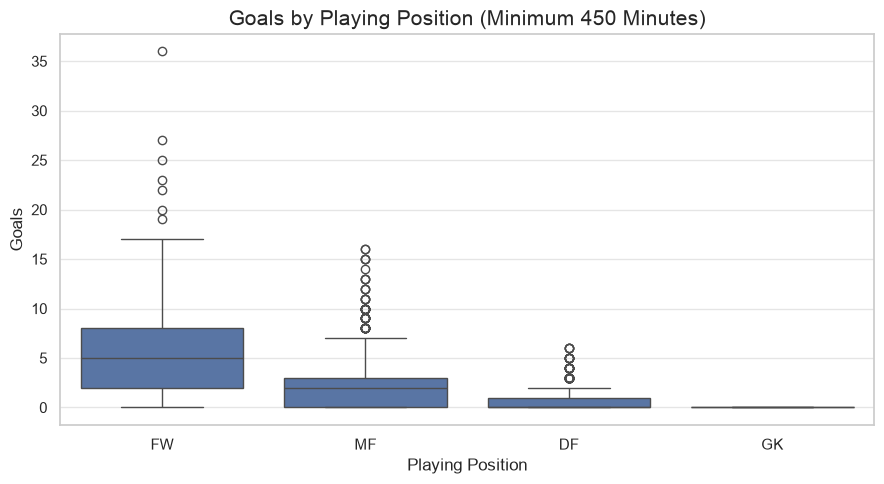

In [12]:
position_data = data[data["Min"] >= 450].copy()
position_data["Main_Position"] = (
    position_data["Pos"].fillna("Unknown").str.split(",").str[0].str.strip()
)

position_order = ["FW", "MF", "DF", "GK"]
position_plot = position_data[
    position_data["Main_Position"].isin(position_order)
]

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=position_plot,
    x="Main_Position",
    y="Gls",
    order=position_order
)
plt.title("Goals by Playing Position (Minimum 450 Minutes)", fontsize=15)
plt.xlabel("Playing Position")
plt.ylabel("Goals")
plt.tight_layout()
plt.savefig("goals_by_position.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Seaborn: correlation heatmap

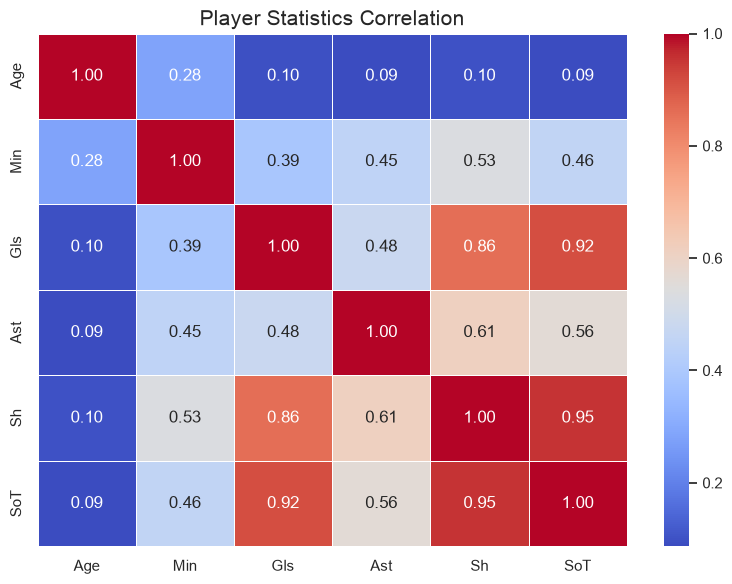

In [13]:
correlation_columns = ["Age", "Min", "Gls", "Ast", "Sh", "SoT"]
correlation_data = data[correlation_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Player Statistics Correlation", fontsize=15)
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Basic web scraping

In [14]:
from urllib.request import Request, urlopen
from html.parser import HTMLParser

class PageParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.in_title = False
        self.current_heading_tag = None
        self.title_parts = []
        self.headings = []
        self.current_heading_parts = []

    def handle_starttag(self, tag, attrs):
        if tag == "title":
            self.in_title = True
        elif tag in ["h1", "h2"]:
            self.current_heading_tag = tag
            self.current_heading_parts = []

    def handle_endtag(self, tag):
        if tag == "title":
            self.in_title = False
        elif tag in ["h1", "h2"] and tag == self.current_heading_tag:
            heading = " ".join(" ".join(self.current_heading_parts).split())
            if heading:
                self.headings.append(heading)
            self.current_heading_tag = None
            self.current_heading_parts = []

    def handle_data(self, data):
        if self.in_title:
            self.title_parts.append(data)
        if self.current_heading_tag:
            self.current_heading_parts.append(data)

    @property
    def title(self):
        return " ".join(" ".join(self.title_parts).split())

In [15]:
url = "https://en.wikipedia.org/wiki/2025%E2%80%9326_Premier_League"
request = Request(
    url,
    headers={"User-Agent": "Mozilla/5.0 (compatible; StudentProject/1.0)"}
)

try:
    with urlopen(request, timeout=15) as response:
        html = response.read().decode("utf-8", errors="ignore")

    parser = PageParser()
    parser.feed(html)

    print("BASIC WEB SCRAPING")
    print("Page title:", parser.title or "Title not found")
    print("\nFirst headings:")

    for heading in parser.headings[:8]:
        print("-", heading)

    with open("scraped_headings.txt", "w", encoding="utf-8") as file:
        file.write("Page title: " + parser.title + "\n")
        file.write("\n".join(parser.headings[:8]))

    print("\nScraped headings saved to scraped_headings.txt")

except Exception as e:
    print("Web scraping could not run:", e)
    print("Check your internet connection or try again later.")
    print("The dataset analysis and charts can still be used.")

BASIC WEB SCRAPING
Page title: 2025–26 Premier League - Wikipedia

First headings:
- Contents
- 2025–26 Premier League
- Summary
- Teams
- League table
- Results
- Season statistics
- Awards

Scraped headings saved to scraped_headings.txt
